# CS781 Capstone — Phase 1 (Architecture 2: Encoder-Decoder)

Name: Aditya Kumar | Roll No: 240059 | Email: adityaj24@iitk.ac.in

In [2]:
!pip install ijson --break-system-packages -q
import os, math, json, time, random, zipfile, csv
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from huggingface_hub import login, hf_hub_download

hf_token = os.environ["HF_TOKEN"]
login(token=hf_token)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_GPUS = torch.cuda.device_count()
print(DEVICE, NUM_GPUS)

cuda 2


In [3]:
SEED = 42
random.seed(SEED); torch.manual_seed(SEED)

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
DATA_SOURCES = [
    "Phase_1_Pretraining/Train/train_supreme_court.json",
    "Phase_1_Pretraining/Train/train_acts.json",
    "Phase_1_Pretraining/Train/train_high_courts.json",
    "Phase_1_Pretraining/Train/train_tribunals.json",
]
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

ARCH_NAME = "encoder_decoder_scratch"

BPE_VOCAB_SIZE = 12000
BPE_TRAIN_CHARS = 8000000
MAX_BPE_WORDS = 100000

SRC_LEN = 384
TGT_LEN = 128
MAX_SRC_LEN = 900
MAX_TGT_LEN = 200

TRAIN_TOKENS = 300000000
VAL_TOKENS = 10000000
BATCH_SIZE = 16
GRAD_ACCUM_STEPS = 4
TRAIN_STEPS = 9200
EVAL_EVERY = 500
WARMUP_STEPS = 200
LR = 3e-4
WEIGHT_DECAY = 0.1

D_MODEL = 768
N_ENC_LAYERS = 6
N_DEC_LAYERS = 6
N_HEADS = 12
D_FF = 3072
DROPOUT = 0.1

TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 400
TEMPERATURE = 0.8
TOP_P = 0.95
CHECKPOINT_EVERY = 250

_data_tag = "-".join(s.split("/")[-1].replace(".json", "") for s in DATA_SOURCES)
RUN_ID = f"{ARCH_NAME}_{_data_tag}"
OUTPUT_DIR = f"/kaggle/working/cs781_phase1/{RUN_ID}"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TOKENIZER_PATH = os.path.join(OUTPUT_DIR, "bpe_tokenizer.json")
TOKENIZED_CACHE_PATH = os.path.join(OUTPUT_DIR, "tokenized_corpus.pt")
CHECKPOINT_PATH = os.path.join(OUTPUT_DIR, "checkpoint.pt")
MODEL_PATH = os.path.join(OUTPUT_DIR, "model.pt")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "loss.png")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
HELDOUT_TRUTH_PATH = os.path.join(OUTPUT_DIR, "heldout_truth.json")
HELDOUT_PRED_PATH = os.path.join(OUTPUT_DIR, "heldout_prediction.json")
LOG_PATH = "/kaggle/working/cs781_phase1/experiment_log.csv"
print(RUN_ID)

encoder_decoder_scratch_train_supreme_court-train_acts-train_high_courts-train_tribunals


In [4]:
def download(path):
    return hf_hub_download(repo_id=HF_DATASET_REPO, filename=path, repo_type="dataset", token=hf_token)

train_file_paths = [download(p) for p in DATA_SOURCES]
test_file_path = download(TEST_FILE)

import ijson

CHARS_PER_TOKEN_EST = 6
CHAR_BUDGET = (TRAIN_TOKENS + VAL_TOKENS) * CHARS_PER_TOKEN_EST + BPE_TRAIN_CHARS + 5000000
MIN_RECORDS = 1000

def stream_records(path, char_budget, min_records):
    collected_chars, n = 0, 0
    with open(path, "rb") as f:
        for rec in ijson.items(f, "item"):
            yield rec
            collected_chars += len(rec.get("text", ""))
            n += 1
            if collected_chars >= char_budget and n >= min_records:
                return

per_file_budget = CHAR_BUDGET // len(train_file_paths)
per_file_min = max(MIN_RECORDS // len(train_file_paths), 300)

records = []
for p in train_file_paths:
    records.extend(stream_records(p, per_file_budget, per_file_min))

random.Random(SEED).shuffle(records)

N_HELDOUT_DOCS = 200
heldout_records = records[-N_HELDOUT_DOCS:]
train_pool_records = records[:-N_HELDOUT_DOCS]
full_train_text = "\n".join(r["text"] for r in train_pool_records)
print(len(records), len(full_train_text))

Phase_1_Pretraining/Train/train_supreme_(…):   0%|          | 0.00/1.32G [00:00<?, ?B/s]

Phase_1_Pretraining/Train/train_acts.jso(…):   0%|          | 0.00/729M [00:00<?, ?B/s]

Phase_1_Pretraining/Train/train_high_cou(…):   0%|          | 0.00/10.7G [00:00<?, ?B/s]

Phase_1_Pretraining/Train/train_tribunal(…):   0%|          | 0.00/6.48G [00:00<?, ?B/s]

test.json: 0.00B [00:00, ?B/s]

261738 1872052005


In [5]:
class ByteLevelBPETokenizer:
    SPECIAL_TOKENS = ["<pad>", "<unk>", "<s>", "</s>"]

    def __init__(self):
        self.merges = {}
        self.id_to_bytes = {i: bytes([i]) for i in range(256)}
        self.special_to_id = {}
        for i, tok in enumerate(self.SPECIAL_TOKENS):
            tid = 256 + i
            self.special_to_id[tok] = tid
            self.id_to_bytes[tid] = tok.encode("utf-8")

    @property
    def vocab_size(self):
        return len(self.id_to_bytes)

    @staticmethod
    def _pair_counts(sequences):
        counts = {}
        for seq, freq in sequences:
            for pair in zip(seq, seq[1:]):
                counts[pair] = counts.get(pair, 0) + freq
        return counts

    @staticmethod
    def _apply_merge(seq, pair, new_id):
        out, i = [], 0
        while i < len(seq):
            if i < len(seq) - 1 and (seq[i], seq[i + 1]) == pair:
                out.append(new_id); i += 2
            else:
                out.append(seq[i]); i += 1
        return out

    def train(self, text, vocab_size, max_words=MAX_BPE_WORDS, verbose=True):
        num_merges = vocab_size - self.vocab_size
        if num_merges <= 0:
            return self

        word_freq = {}
        for word in text.split():
            word_freq[word] = word_freq.get(word, 0) + 1
        if len(word_freq) > max_words:
            word_freq = dict(sorted(word_freq.items(), key=lambda kv: -kv[1])[:max_words])
        sequences = [[list(word.encode("utf-8")), freq] for word, freq in word_freq.items()]

        next_id = self.vocab_size
        for step in range(num_merges):
            counts = self._pair_counts(sequences)
            if not counts:
                break
            best_pair = max(counts, key=counts.get)
            self.merges[best_pair] = next_id
            self.id_to_bytes[next_id] = self.id_to_bytes[best_pair[0]] + self.id_to_bytes[best_pair[1]]
            for entry in sequences:
                entry[0] = self._apply_merge(entry[0], best_pair, next_id)
            if verbose and (step + 1) % 1000 == 0:
                print(step + 1, next_id + 1)
            next_id += 1
        return self

    def encode(self, text):
        ids = []
        for word in text.split():
            seq = list(word.encode("utf-8"))
            while len(seq) > 1:
                mergeable = [p for p in zip(seq, seq[1:]) if p in self.merges]
                if not mergeable:
                    break
                pair = min(mergeable, key=lambda p: self.merges[p])
                seq = self._apply_merge(seq, pair, self.merges[pair])
            ids.extend(seq)
            ids.append(self.special_to_id["</s>"])
        return ids

    def encode_to_array(self, text, max_tokens):
        arr = np.empty(max_tokens, dtype=np.int32)
        n = 0
        for word in text.split():
            seq = list(word.encode("utf-8"))
            while len(seq) > 1:
                mergeable = [p for p in zip(seq, seq[1:]) if p in self.merges]
                if not mergeable:
                    break
                pair = min(mergeable, key=lambda p: self.merges[p])
                seq = self._apply_merge(seq, pair, self.merges[pair])
            seq.append(self.special_to_id["</s>"])
            for t in seq:
                if n >= max_tokens:
                    return arr[:n]
                arr[n] = t; n += 1
        return arr[:n]

    def decode(self, ids):
        words, current = [], []
        for i in ids:
            if i == self.special_to_id["</s>"]:
                if current:
                    words.append(b"".join(self.id_to_bytes.get(int(t), b"") for t in current).decode("utf-8", errors="ignore"))
                    current = []
            else:
                current.append(i)
        if current:
            words.append(b"".join(self.id_to_bytes.get(int(t), b"") for t in current).decode("utf-8", errors="ignore"))
        return " ".join(words)

    def save(self, path):
        merges_serializable = {f"{a},{b}": nid for (a, b), nid in self.merges.items()}
        with open(path, "w", encoding="utf-8") as f:
            json.dump({"merges": merges_serializable}, f)

    @classmethod
    def load(cls, path):
        tok = cls()
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        for pair_str, nid in data["merges"].items():
            a, b = (int(x) for x in pair_str.split(","))
            tok.merges[(a, b)] = nid
            tok.id_to_bytes[nid] = tok.id_to_bytes[a] + tok.id_to_bytes[b]
        return tok

In [6]:
if os.path.exists(TOKENIZER_PATH):
    tokenizer = ByteLevelBPETokenizer.load(TOKENIZER_PATH)
else:
    tokenizer = ByteLevelBPETokenizer().train(full_train_text[:BPE_TRAIN_CHARS], BPE_VOCAB_SIZE)
    tokenizer.save(TOKENIZER_PATH)

VOCAB_SIZE = tokenizer.vocab_size
BOS_ID = tokenizer.special_to_id["<s>"]
print(VOCAB_SIZE, BOS_ID)

1000 1260
2000 2260
3000 3260
4000 4260
5000 5260
6000 6260
7000 7260
8000 8260
9000 9260
10000 10260
11000 11260
12000 258


In [7]:
def to_tensor(x):
    return torch.from_numpy(x) if isinstance(x, np.ndarray) else x

if os.path.exists(TOKENIZED_CACHE_PATH):
    cache = torch.load(TOKENIZED_CACHE_PATH, weights_only=False)
    train_ids = to_tensor(cache["train_ids"])
    val_ids = to_tensor(cache["val_ids"])
else:
    all_ids = tokenizer.encode_to_array(full_train_text, TRAIN_TOKENS + VAL_TOKENS)
    split = int(len(all_ids) * (TRAIN_TOKENS / (TRAIN_TOKENS + VAL_TOKENS)))
    train_ids = torch.from_numpy(all_ids[:split].astype(np.int64, copy=True))
    val_ids = torch.from_numpy(all_ids[split:].astype(np.int64, copy=True))
    torch.save({"train_ids": train_ids, "val_ids": val_ids}, TOKENIZED_CACHE_PATH)

del full_train_text
print(len(train_ids), len(val_ids))

CHUNK_LEN = SRC_LEN + TGT_LEN

def make_seq2seq_dataset(ids, chunk_len, src_len, tgt_len, bos_id):
    n = (len(ids) // chunk_len) * chunk_len
    blocks = ids[:n].clone().view(-1, chunk_len)
    src = blocks[:, :src_len]
    tgt = blocks[:, src_len:]
    bos_col = torch.full((tgt.size(0), 1), bos_id, dtype=torch.long)
    tgt_input = torch.cat([bos_col, tgt[:, :-1]], dim=1)
    tgt_target = tgt
    return src, tgt_input, tgt_target

train_src, train_tgt_in, train_tgt_out = make_seq2seq_dataset(train_ids, CHUNK_LEN, SRC_LEN, TGT_LEN, BOS_ID)
val_src, val_tgt_in, val_tgt_out = make_seq2seq_dataset(val_ids, CHUNK_LEN, SRC_LEN, TGT_LEN, BOS_ID)

class Seq2SeqDataset(Dataset):
    def __init__(self, src, tgt_in, tgt_out):
        self.src, self.tgt_in, self.tgt_out = src, tgt_in, tgt_out
    def __len__(self):
        return len(self.src)
    def __getitem__(self, idx):
        return self.src[idx], self.tgt_in[idx], self.tgt_out[idx]

train_loader = DataLoader(Seq2SeqDataset(train_src, train_tgt_in, train_tgt_out), batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader = DataLoader(Seq2SeqDataset(val_src, val_tgt_in, val_tgt_out), batch_size=BATCH_SIZE, shuffle=False, drop_last=True)
print(train_src.shape, train_tgt_in.shape, train_tgt_out.shape)

300000000 10000000
torch.Size([585937, 384]) torch.Size([585937, 128]) torch.Size([585937, 128])


In [8]:
def split_prompt_continuation(text, prompt_words=512, cont_words=128):
    words = text.split()
    if len(words) < prompt_words + 20:
        return None
    return " ".join(words[:prompt_words]), " ".join(words[prompt_words: prompt_words + cont_words])

heldout_truth, heldout_prompts = {}, {}
for i, rec in enumerate(heldout_records):
    r = split_prompt_continuation(rec["text"])
    if r is None:
        continue
    ex_id = str(i + 1)
    heldout_prompts[ex_id] = {"text": r[0]}
    heldout_truth[ex_id] = {"text": r[1]}

with open(HELDOUT_TRUTH_PATH, "w", encoding="utf-8") as f:
    json.dump(heldout_truth, f, ensure_ascii=False, indent=2)
print(len(heldout_truth))

74


In [9]:
class MultiHeadAttention(nn.Module):
    """Multi-head self-attention and cross-attention."""
    def __init__(self, d_model, n_heads, dropout=0.0, causal=False, max_seq_len=None):
        super().__init__()
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.scale = 1.0 / math.sqrt(self.d_head)
        self.causal = causal
        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.k_proj = nn.Linear(d_model, d_model, bias=False)
        self.v_proj = nn.Linear(d_model, d_model, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
        if causal:
            mask = torch.tril(torch.ones(max_seq_len, max_seq_len, dtype=torch.bool))
            self.register_buffer("causal_mask", mask, persistent=False)

    def forward(self, x_q, x_kv):
        B, T, C = x_q.shape
        S = x_kv.shape[1]
        q = self.q_proj(x_q).view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        k = self.k_proj(x_kv).view(B, S, self.n_heads, self.d_head).transpose(1, 2)
        v = self.v_proj(x_kv).view(B, S, self.n_heads, self.d_head).transpose(1, 2)
        scores = torch.matmul(q, k.transpose(-2, -1)) * self.scale
        if self.causal:
            scores = scores.masked_fill(~self.causal_mask[:T, :S], float("-inf"))
        attn = self.attn_dropout(torch.softmax(scores, dim=-1))
        out = torch.matmul(attn, v).transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_dropout(self.out_proj(out))


def sinusoidal_positional_encoding(max_len, d_model):
    pe = torch.zeros(max_len, d_model)
    position = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
    div_term = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) * (-math.log(10000.0) / d_model))
    pe[:, 0::2] = torch.sin(position * div_term)
    pe[:, 1::2] = torch.cos(position * div_term)
    return pe


def feed_forward(d_model, d_ff, dropout):
    return nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, d_model), nn.Dropout(dropout))


class EncoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.self_attn = MultiHeadAttention(d_model, n_heads, dropout, causal=False)
        self.ln2 = nn.LayerNorm(d_model)
        self.ff = feed_forward(d_model, d_ff, dropout)

    def forward(self, x):
        x = x + self.self_attn(self.ln1(x), self.ln1(x))
        x = x + self.ff(self.ln2(x))
        return x


class DecoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, max_tgt_len, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.self_attn = MultiHeadAttention(d_model, n_heads, dropout, causal=True, max_seq_len=max_tgt_len)
        self.ln2 = nn.LayerNorm(d_model)
        self.cross_attn = MultiHeadAttention(d_model, n_heads, dropout, causal=False)
        self.ln3 = nn.LayerNorm(d_model)
        self.ff = feed_forward(d_model, d_ff, dropout)

    def forward(self, x, enc_out):
        x = x + self.self_attn(self.ln1(x), self.ln1(x))
        x = x + self.cross_attn(self.ln2(x), enc_out)
        x = x + self.ff(self.ln3(x))
        return x


class EncoderDecoderLM(nn.Module):
    def __init__(self, vocab_size, d_model, n_enc_layers, n_dec_layers, n_heads, d_ff,
                 max_src_len, max_tgt_len, dropout=0.1):
        super().__init__()
        self.max_src_len = max_src_len
        self.max_tgt_len = max_tgt_len
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.register_buffer("enc_pos", sinusoidal_positional_encoding(max_src_len, d_model), persistent=False)
        self.register_buffer("dec_pos", sinusoidal_positional_encoding(max_tgt_len, d_model), persistent=False)
        self.drop = nn.Dropout(dropout)
        self.encoder_blocks = nn.ModuleList([EncoderBlock(d_model, n_heads, d_ff, dropout) for _ in range(n_enc_layers)])
        self.decoder_blocks = nn.ModuleList([DecoderBlock(d_model, n_heads, d_ff, max_tgt_len, dropout) for _ in range(n_dec_layers)])
        self.enc_ln_f = nn.LayerNorm(d_model)
        self.dec_ln_f = nn.LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        self.lm_head.weight = self.token_emb.weight
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if isinstance(module, nn.Linear) and module.bias is not None:
                nn.init.zeros_(module.bias)

    def encode(self, src_ids):
        T = src_ids.shape[1]
        x = self.drop(self.token_emb(src_ids) + self.enc_pos[:T].unsqueeze(0))
        for block in self.encoder_blocks:
            x = block(x)
        return self.enc_ln_f(x)

    def decode(self, tgt_input_ids, enc_out):
        T = tgt_input_ids.shape[1]
        x = self.drop(self.token_emb(tgt_input_ids) + self.dec_pos[:T].unsqueeze(0))
        for block in self.decoder_blocks:
            x = block(x, enc_out)
        return self.lm_head(self.dec_ln_f(x))

    def forward(self, src_ids, tgt_input_ids, tgt_target_ids=None):
        enc_out = self.encode(src_ids)
        logits = self.decode(tgt_input_ids, enc_out)
        loss = None
        if tgt_target_ids is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), tgt_target_ids.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, src_ids, bos_id, max_new_tokens, temperature=1.0, top_p=0.95):
        self.eval()
        enc_out = self.encode(src_ids[:, -self.max_src_len:])
        dec_ids = torch.full((src_ids.size(0), 1), bos_id, dtype=torch.long, device=src_ids.device)
        for _ in range(max_new_tokens):
            logits = self.decode(dec_ids[:, -self.max_tgt_len:], enc_out)
            logits = logits[:, -1, :] / max(temperature, 1e-5)
            probs = torch.softmax(logits, dim=-1)
            sorted_probs, sorted_idx = torch.sort(probs, descending=True, dim=-1)
            cum_probs = torch.cumsum(sorted_probs, dim=-1)
            cutoff = (cum_probs > top_p).float().argmax(dim=-1, keepdim=True)
            mask = torch.arange(sorted_probs.size(-1), device=src_ids.device).unsqueeze(0) > cutoff
            sorted_probs = sorted_probs.masked_fill(mask, 0.0)
            sorted_probs = sorted_probs / sorted_probs.sum(dim=-1, keepdim=True)
            next_sorted = torch.multinomial(sorted_probs, num_samples=1)
            next_token = torch.gather(sorted_idx, -1, next_sorted)
            dec_ids = torch.cat([dec_ids, next_token], dim=1)
        return dec_ids[:, 1:]

In [10]:
def build_model(arch_name):
    if arch_name == "encoder_decoder_scratch":
        return EncoderDecoderLM(VOCAB_SIZE, D_MODEL, N_ENC_LAYERS, N_DEC_LAYERS, N_HEADS, D_FF,
                                 MAX_SRC_LEN, MAX_TGT_LEN, DROPOUT)
    raise ValueError(arch_name)

raw_model = build_model(ARCH_NAME).to(DEVICE)
n_params = sum(p.numel() for p in raw_model.parameters())
print(n_params / 1e6)
assert 50e6 <= n_params <= 300e6

if NUM_GPUS > 1:
    model = nn.DataParallel(raw_model)
else:
    model = raw_model

108.401664


In [11]:
def get_lr(step, total_steps, warmup_steps, base_lr):
    if step < warmup_steps:
        return base_lr * step / max(1, warmup_steps)
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * base_lr * (1 + math.cos(math.pi * progress))

def evaluate(loader, max_batches=50):
    model.eval()
    losses = []
    with torch.no_grad():
        for i, (src, tgt_in, tgt_out) in enumerate(loader):
            if i >= max_batches:
                break
            src, tgt_in, tgt_out = src.to(DEVICE), tgt_in.to(DEVICE), tgt_out.to(DEVICE)
            with torch.autocast(device_type="cuda", enabled=torch.cuda.is_available()):
                _, loss = model(src, tgt_in, tgt_out)
                loss = loss.mean()
            losses.append(loss.item())
    model.train()
    return sum(losses) / max(1, len(losses))

def save_checkpoint(path, step, train_loss_history, val_loss_history, step_history, elapsed_seconds):
    tmp_path = path + ".tmp"
    torch.save({
        "step": step, "model_state": raw_model.state_dict(), "optimizer_state": optimizer.state_dict(),
        "scaler_state": scaler.state_dict(), "train_loss_history": train_loss_history,
        "val_loss_history": val_loss_history, "step_history": step_history, "elapsed_seconds": elapsed_seconds,
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_state": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
        "python_rng_state": random.getstate(),
        "run_config": {"ARCH_NAME": ARCH_NAME, "D_MODEL": D_MODEL, "N_ENC_LAYERS": N_ENC_LAYERS,
                       "N_DEC_LAYERS": N_DEC_LAYERS, "N_HEADS": N_HEADS, "D_FF": D_FF,
                       "MAX_SRC_LEN": MAX_SRC_LEN, "MAX_TGT_LEN": MAX_TGT_LEN, "VOCAB_SIZE": VOCAB_SIZE},
    }, tmp_path)
    os.replace(tmp_path, path)

def load_checkpoint(path):
    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    cfg = ckpt["run_config"]
    mismatches = [k for k, v in cfg.items() if str(v) != str(globals()[k])]
    if mismatches:
        raise ValueError(mismatches)
    raw_model.load_state_dict(ckpt["model_state"])
    optimizer.load_state_dict(ckpt["optimizer_state"])
    scaler.load_state_dict(ckpt["scaler_state"])
    torch.set_rng_state(ckpt["torch_rng_state"])
    if ckpt["cuda_rng_state"] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(ckpt["cuda_rng_state"])
    random.setstate(ckpt["python_rng_state"])
    return ckpt["step"], ckpt["train_loss_history"], ckpt["val_loss_history"], ckpt["step_history"], ckpt["elapsed_seconds"]


optimizer = torch.optim.AdamW(raw_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY, betas=(0.9, 0.95))
scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

if os.path.exists(CHECKPOINT_PATH):
    step, train_loss_history, val_loss_history, step_history, prev_elapsed = load_checkpoint(CHECKPOINT_PATH)
else:
    step, train_loss_history, val_loss_history, step_history, prev_elapsed = 0, [], [], [], 0.0

t0 = time.time()
model.train()
def repeat_loader(loader):
    while True:
        yield from loader


data_iter = iter(repeat_loader(train_loader))

while step < TRAIN_STEPS:
    optimizer.zero_grad(set_to_none=True)
    accum_loss = 0.0
    for _ in range(GRAD_ACCUM_STEPS):
        src, tgt_in, tgt_out = next(data_iter)
        src, tgt_in, tgt_out = src.to(DEVICE), tgt_in.to(DEVICE), tgt_out.to(DEVICE)
        with torch.autocast(device_type="cuda", enabled=torch.cuda.is_available()):
            _, loss = model(src, tgt_in, tgt_out)
            loss = loss.mean() / GRAD_ACCUM_STEPS
        scaler.scale(loss).backward()
        accum_loss += loss.item()

    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(raw_model.parameters(), 1.0)
    lr_now = get_lr(step, TRAIN_STEPS, WARMUP_STEPS, LR)
    for g in optimizer.param_groups:
        g["lr"] = lr_now
    scaler.step(optimizer)
    scaler.update()
    step += 1

    if step % 50 == 0:
        train_loss_history.append(accum_loss); step_history.append(step)
        print(step, accum_loss, lr_now)

    if step % EVAL_EVERY == 0 or step == TRAIN_STEPS:
        v_loss = evaluate(val_loader)
        val_loss_history.append((step, v_loss))
        print("eval", step, v_loss, math.exp(v_loss))

    if step % CHECKPOINT_EVERY == 0 or step == TRAIN_STEPS:
        elapsed = prev_elapsed + (time.time() - t0)
        save_checkpoint(CHECKPOINT_PATH, step, train_loss_history, val_loss_history, step_history, elapsed)

training_time = prev_elapsed + (time.time() - t0)
print(training_time / 3600)

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


50 4.960445284843445 7.35e-05
100 4.44067120552063 0.00014849999999999998
150 4.190583229064941 0.00022349999999999998
200 4.031145334243774 0.0002985
250 3.986294746398926 0.00029997805894217363
300 3.8698705434799194 0.0002999104422532459
350 3.8475266695022583 0.0002997971613913928
400 3.8153138756752014 0.00029963825086306217
450 3.900151252746582 0.00029943375907394036
500 3.8189806938171387 0.0002991837483142073
eval 500 3.813514680862427 45.309407448003604
550 3.8578436970710754 0.0002988882947395623
600 3.885064482688904 0.0002985474883480264
650 3.650826930999756 0.0002981614329525278
700 3.6445001363754272 0.00029773024614927984
750 3.7163822650909424 0.0002972540592819598
800 3.6123969554901123 0.0002967330174017004
850 3.610515832901001 0.0002961672792229057
900 3.554714620113373 0.0002955570170749055
950 3.612250804901123 0.00029490241684946184
1000 3.4717137813568115 0.0002942036779441446
eval 1000 3.468904595375061 32.101558982030674
1050 3.4858807921409607 0.00029346101

2.593277023434639 13.373525228790633


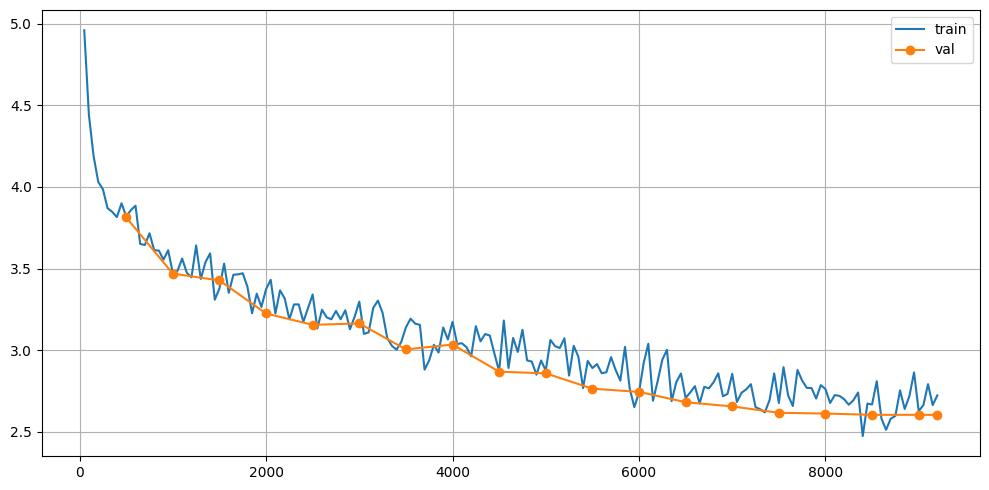

In [12]:
import matplotlib.pyplot as plt

final_val_loss = evaluate(val_loader, max_batches=200)
final_val_ppl = math.exp(final_val_loss)
print(final_val_loss, final_val_ppl)

plt.figure(figsize=(10, 5))
plt.plot(step_history, train_loss_history, label="train")
if val_loss_history:
    vs, vl = zip(*val_loss_history)
    plt.plot(vs, vl, label="val", marker="o")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
plt.show()

In [13]:
torch.save({
    "state_dict": raw_model.state_dict(),
    "config": {"vocab_size": VOCAB_SIZE, "d_model": D_MODEL, "n_enc_layers": N_ENC_LAYERS,
               "n_dec_layers": N_DEC_LAYERS, "n_heads": N_HEADS, "d_ff": D_FF,
               "max_src_len": MAX_SRC_LEN, "max_tgt_len": MAX_TGT_LEN, "dropout": DROPOUT,
               "arch_name": ARCH_NAME},
}, MODEL_PATH)

In [14]:
def trim_to_words(text, n_words):
    return " ".join(text.split()[:n_words])

def generate_continuation(prompt_text, max_new_tokens=MAX_GENERATION_TOKENS):
    src_ids = tokenizer.encode(prompt_text)[-MAX_SRC_LEN:]
    src = torch.tensor([src_ids], dtype=torch.long, device=DEVICE)
    out = raw_model.generate(src, BOS_ID, max_new_tokens=max_new_tokens, temperature=TEMPERATURE, top_p=TOP_P)
    new_text = tokenizer.decode(out[0].tolist())
    return trim_to_words(new_text, TARGET_GENERATION_WORDS)

def generate_for_dataset(prompt_dict):
    predictions = {}
    for i, (ex_id, rec) in enumerate(prompt_dict.items()):
        predictions[ex_id] = {"text": generate_continuation(rec["text"])}
        if (i + 1) % 25 == 0:
            print(i + 1, len(prompt_dict))
    return predictions

raw_model.eval()

EncoderDecoderLM(
  (token_emb): Embedding(12000, 768)
  (drop): Dropout(p=0.1, inplace=False)
  (encoder_blocks): ModuleList(
    (0-5): 6 x EncoderBlock(
      (ln1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (self_attn): MultiHeadAttention(
        (q_proj): Linear(in_features=768, out_features=768, bias=False)
        (k_proj): Linear(in_features=768, out_features=768, bias=False)
        (v_proj): Linear(in_features=768, out_features=768, bias=False)
        (out_proj): Linear(in_features=768, out_features=768, bias=False)
        (attn_dropout): Dropout(p=0.1, inplace=False)
        (resid_dropout): Dropout(p=0.1, inplace=False)
      )
      (ln2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (ff): Sequential(
        (0): Linear(in_features=768, out_features=3072, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=3072, out_features=768, bias=True)
        (3): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (deco

In [15]:
heldout_preds = generate_for_dataset(heldout_prompts)
with open(HELDOUT_PRED_PATH, "w", encoding="utf-8") as f:
    json.dump(heldout_preds, f, ensure_ascii=False, indent=2)

25 74
50 74


In [16]:
!pip install bert-score --break-system-packages -q
!python /kaggle/input/datasets/adityakumar344/evaluate-phase1-script/evaluate_phase1.py --truth {HELDOUT_TRUTH_PATH} --prediction {HELDOUT_PRED_PATH}

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 2.1 MB/s eta 0:00:00
config.json: 100%|█████████████████████████████| 482/482 [00:00<00:00, 2.08MB/s]
tokenizer_config.json: 100%|██████████████████| 25.0/25.0 [00:00<00:00, 153kB/s]
vocab.json: 899kB [00:00, 17.6MB/s]
merges.txt: 456kB [00:00, 3.31MB/s]
tokenizer.json: 1.36MB [00:00, 10.6MB/s]
model.safetensors: 100%|████████████████████| 1.42G/1.42G [00:07<00:00, 202MB/s]
Loading weights: 100%|█| 389/389 [00:00<00:00, 1559.40it/s, Materializing param=
RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.d

In [17]:
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

official_predictions = generate_for_dataset(test_data)
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(official_predictions, f, ensure_ascii=False, indent=2)

25 1000
50 1000
75 1000
100 1000
125 1000
150 1000
175 1000
200 1000
225 1000
250 1000
275 1000
300 1000
325 1000
350 1000
375 1000
400 1000
425 1000
450 1000
475 1000
500 1000
525 1000
550 1000
575 1000
600 1000
625 1000
650 1000
675 1000
700 1000
725 1000
750 1000
775 1000
800 1000
825 1000
850 1000
875 1000
900 1000
925 1000
950 1000
975 1000
1000 1000


In [18]:
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    zf.write(PREDICTION_PATH, arcname="prediction.json")
print(SUBMISSION_ZIP)

/kaggle/working/cs781_phase1/encoder_decoder_scratch_train_supreme_court-train_acts-train_high_courts-train_tribunals/submission.zip


In [19]:
def log_run():
    row = {
        "run_id": RUN_ID, "arch": ARCH_NAME, "data_sources": ";".join(DATA_SOURCES),
        "vocab_size": VOCAB_SIZE, "train_tokens": len(train_ids), "src_len": SRC_LEN, "tgt_len": TGT_LEN,
        "d_model": D_MODEL, "n_enc_layers": N_ENC_LAYERS, "n_dec_layers": N_DEC_LAYERS,
        "n_heads": N_HEADS, "d_ff": D_FF, "params_M": round(n_params / 1e6, 2), "train_steps": TRAIN_STEPS,
        "final_val_loss": round(final_val_loss, 6), "final_val_ppl": round(final_val_ppl, 4),
        "training_hours": round(training_time / 3600, 3),
    }
    write_header = not os.path.exists(LOG_PATH)
    with open(LOG_PATH, "a", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(row.keys()))
        if write_header:
            writer.writeheader()
        writer.writerow(row)

log_run()